In [2]:
import os

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from bluemath_tk.teslakit.alr import ALR_WRP

In [3]:
#### Load Data
pcs_df_with_kma = pd.read_csv(os.path.join("..", "..", "outputs", "alr", "pcs_with_kma.csv"))
pcs_df_with_kma = pcs_df_with_kma.rename(columns={'kma':'bmus', 'Unnamed: 0':'time'})

pcs_df_with_kma = pcs_df_with_kma.set_index('time')
pcs_df_with_kma.index = pd.to_datetime(pcs_df_with_kma.index)

pcs_df_with_kma['bmus'] = pcs_df_with_kma['bmus'] + 1
pcs_df_with_kma['bmus'] = pcs_df_with_kma['bmus'].astype(int)

In [4]:
alr_terms = {
    "mk_order": 1,
    "constant": True,
    "long_term": False,
    "seasonality": (True, [2,4,6]),
    "covariates": (
        False, []
    ),
}

data_ds = pcs_df_with_kma[['bmus']].to_xarray()

alr_model = ALR_WRP(p_base="outputs/alr")
alr_model.SetFitData(
    cluster_size=36,
    xds_bmus_fit=data_ds,
    d_terms_settings=alr_terms,
)
alr_model.FitModel(max_iter=1000)


Fitting autoregressive logistic model ...
Optimization done in 47.02 seconds



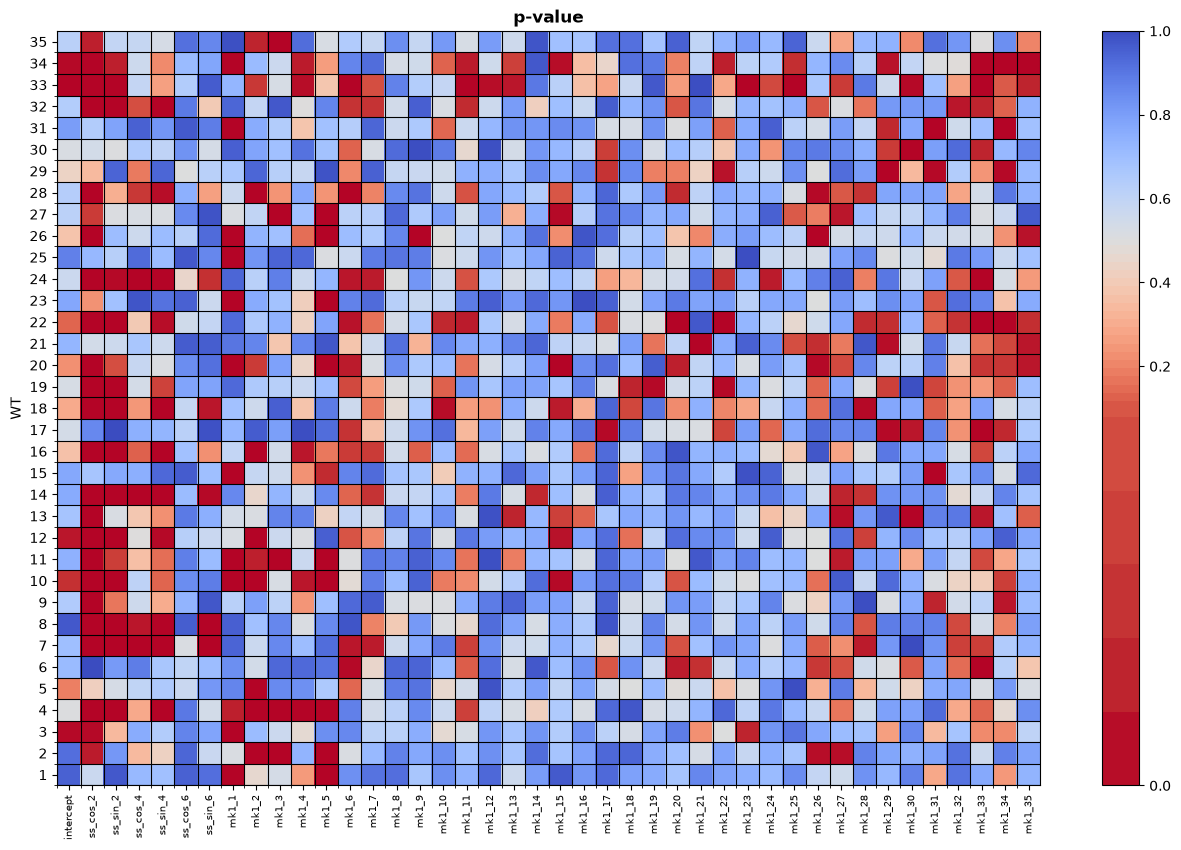

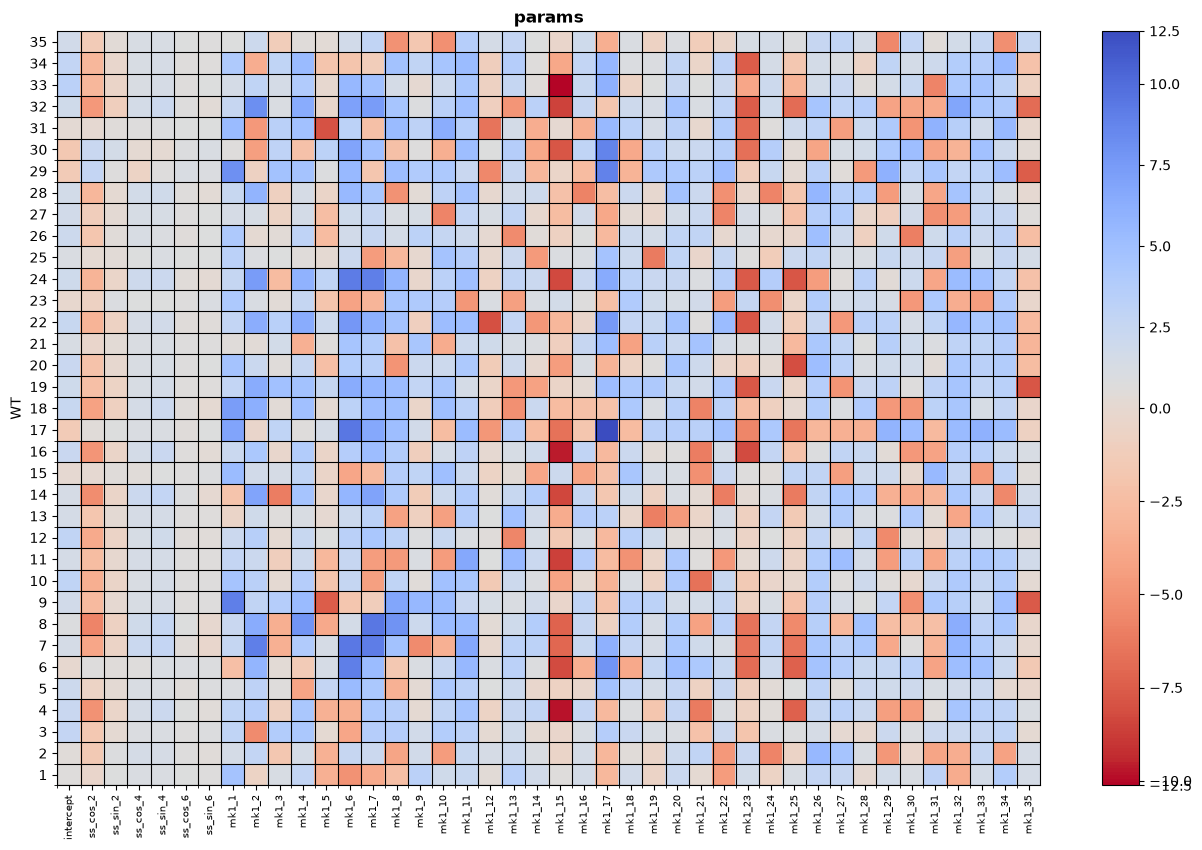

In [5]:
alr_model.Report_Fit()

In [11]:
simulation = alr_model.Simulate(num_sims=100, time_sim=data_ds.time.values)

ALR model fit   : 1940-01-01 --- 2026-09-30
ALR model sim   : 1940-01-01 --- 2026-09-30

Launching 100 simulations...

Sim. Num. 100: 100%|██████████| 31684/31684 [00:03<00:00, 8341.39it/s]



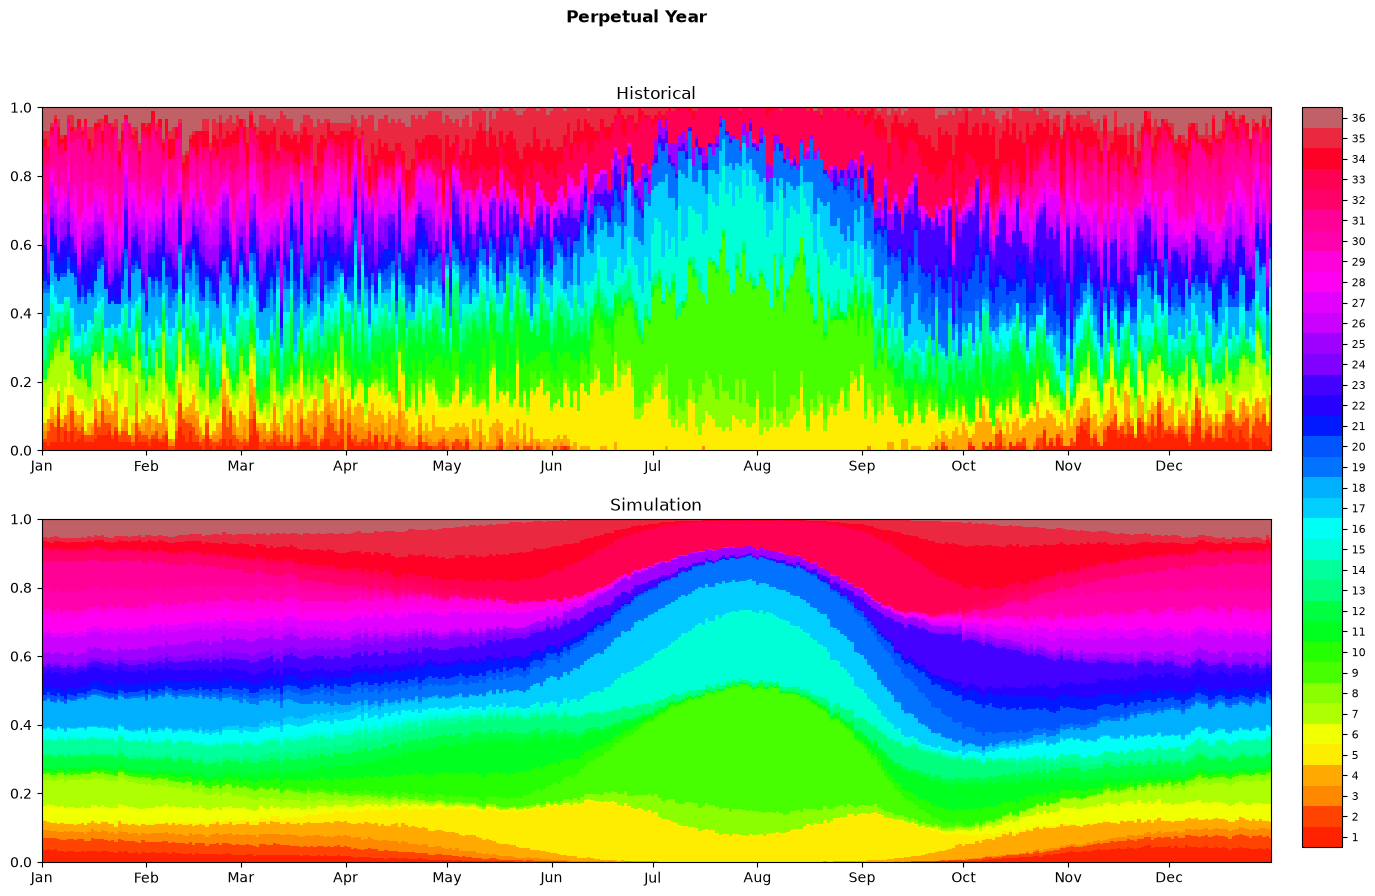

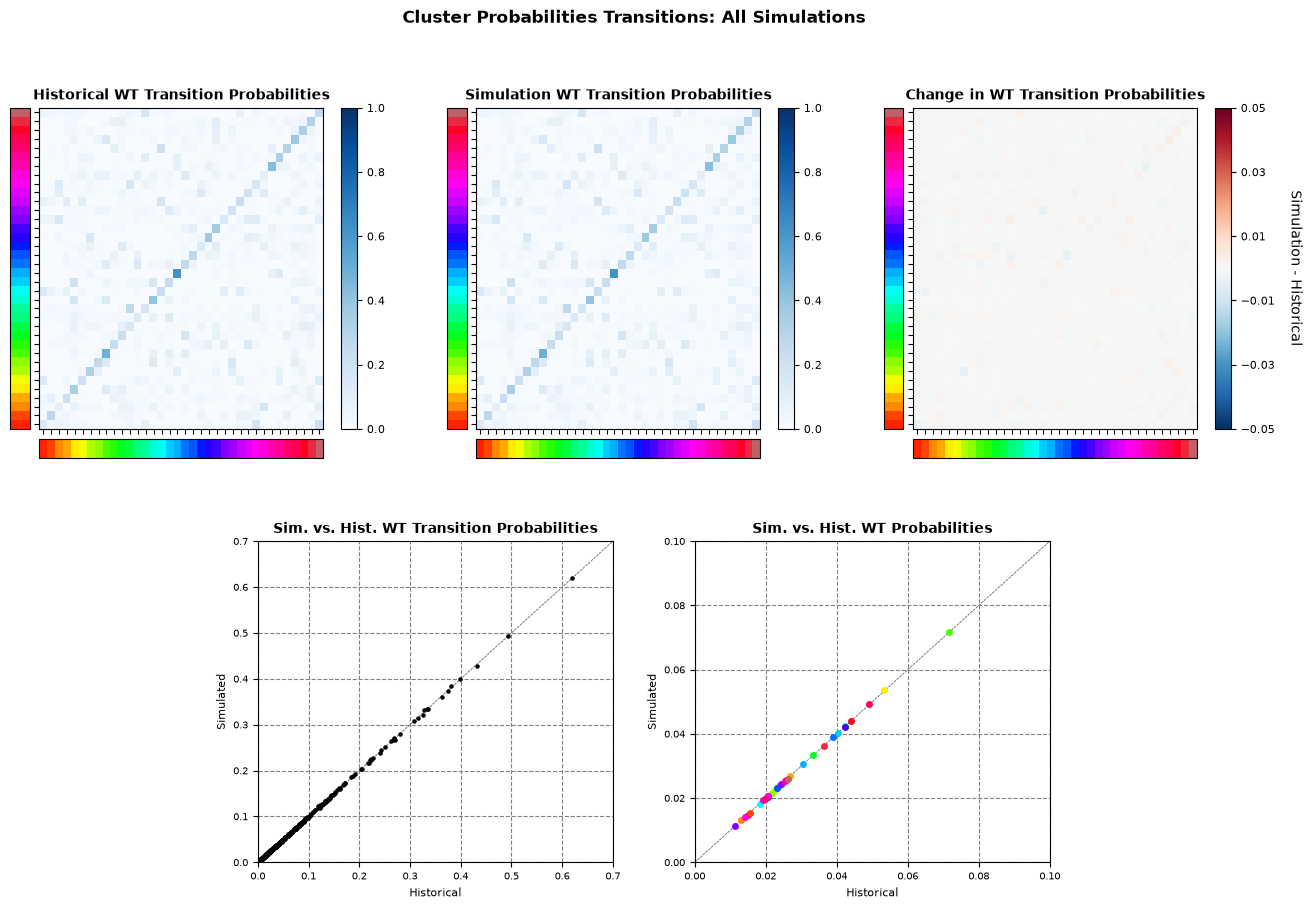

[<Figure size 1585.64x980 with 3 Axes>, <Figure size 1585.64x980 with 14 Axes>]

In [12]:
alr_model.Report_Sim()

In [15]:
simulation['evbmus_sims'] = simulation['evbmus_sims'] -1

In [19]:
simulation.to_netcdf('/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/wt_var_testing/outputs/alr/wt_alr_sim_bmus.nc')